# 16. 학습 데이터 양(25/50/100%)에 따른 Scratch vs Transfer(DS)

질문: **학습 데이터가 줄수록 사전학습(Transfer)의 이점이 커지는가?** 공식 도전 과제 "학습 데이터 25/50/100% 비교"를 사람 단위 3-fold CV로 했습니다.

- 학습 데이터만 줄이고, 검증 사람의 데이터는 항상 100%입니다. Test는 쓰지 않습니다.
- 부분 집합: 공식 파일과 같은 규칙(사람×클래스마다 정확히 25%·50%, 25% ⊂ 50%). 공식 Train 16명은 공식 선택을 그대로, Val 3명은 같은 규칙으로 seed 2026(`data/splits/cv3_train_subsets.csv`, 검사 32항목).
- 고정: letterbox 224, 증강 없음, AdamW, 최대 50 epoch, Early Stopping patience 5, seed 42. Full 100%는 `CV1-letterbox`(같은 데이터·순서 확인).
- **판정 기준(실행 전 `experiments/DS/PLAN.md`)**: Gap_f(p) = F1(Full) − F1(Scratch)
  - Q1 지지: 세 fold 모두 Gap(25) > Gap(100)이고 평균 차이 ≥ +0.020 / 반대: Gap(25) < Gap(100)인 fold 2개 이상 / 그 밖: 구분 불가
  - Q2 전략별 데이터 민감도 Drop = F1(100) − F1(25), Q3 25%에서 FE − Scratch(기술만)
- seed 1개, fold는 독립 표본이 아님. fold 점수는 Early Stopping과 같은 데이터라 낙관적입니다.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, class_names, set_korean_font
from dataset import load_cv

print("font:", set_korean_font())
pd.set_option("display.width", 220)
NAMES = class_names()
EXP = ROOT / "experiments"
STRATS, PCTS, FOLDS = ("scratch", "fe", "full"), (25, 50, 100), (1, 2, 3)
LABEL = {"scratch": "Scratch", "fe": "FE", "full": "Full FT"}
SUB_SHA = "e3fcec1860899fa00fd57ca75f73e42a8ecf877cdff6183a2626937e9bdef21f"
ntrain = {(f, p): len(load_cv(f, p)[0]) for f in FOLDS for p in PCTS}

rows = []
for f in FOLDS:
    for p in PCTS:
        for s in STRATS:
            dd = EXP / ("CV1-letterbox-f%d" % f if (s, p) == ("full", 100) else f"DS-p{p}-f{f}") / s
            sm = json.loads((dd / "summary.json").read_text(encoding="utf-8")); cf = json.loads((dd / "config.json").read_text(encoding="utf-8"))
            assert (cf["cv_fold"], cf["train_pct"], cf["strategy"], cf["seed"], cf["preprocess"], cf["input_size"], cf["augment"]) == (f, p, s, 42, "letterbox", 224, "none"), dd
            assert cf.get("cv_subsets_sha256") == (SUB_SHA if p != 100 else None), dd
            h = pd.read_csv(dd / "history.csv"); rec = sm["val"]["per_class"]["recall"]
            rows.append({"전략": s, "비율": p, "fold": f, "학습 장수": ntrain[(f, p)], "Macro F1": sm["val"]["macro_f1"], "Acc": sm["val"]["accuracy"],
                         "최저 Recall": min(rec.values()), "최저 클래스": min(rec, key=rec.get), **{f"R:{k}": v for k, v in rec.items()},
                         "best/멈춤": f"{sm['best_epoch']}/{sm['epochs_run']}", "Best−Last": sm["val"]["macro_f1"] - h.val_macro_f1.iloc[-1],
                         "epoch당(초)": sm["mean_train_epoch_s"], "전체(분)": sm["total_time_s"] / 60})
ds = pd.DataFrame(rows)
print(len(ds), "runs")
ds.pivot_table(index=["전략", "비율"], columns="fold", values="Macro F1").reindex(STRATS, level=0).round(4).assign(
    평균=lambda t: t.mean(axis=1).round(4))

font: Malgun Gothic


27 runs


fold              1       2       3      평균
전략      비율                                 
scratch 25   0.7344  0.6384  0.6835  0.6854
        50   0.7377  0.7269  0.7214  0.7287
        100  0.7295  0.7682  0.7627  0.7535
fe      25   0.6999  0.7376  0.7328  0.7234
        50   0.6907  0.7633  0.7331  0.7290
        100  0.7266  0.7694  0.7483  0.7481
full    25   0.8141  0.8409  0.8300  0.8283
        50   0.8306  0.8436  0.8437  0.8393
        100  0.8193  0.8730  0.8423  0.8449

## 1. Q1: 데이터가 적을수록 Transfer 이점이 커지는가

In [2]:
F = ds.set_index(["전략", "비율", "fold"])["Macro F1"]
gap = pd.DataFrame({p: [F["full", p, f] - F["scratch", p, f] for f in FOLDS] for p in PCTS}, index=[f"fold {f}" for f in FOLDS])
gap.loc["평균"] = gap.mean()
d25 = gap.loc[[f"fold {f}" for f in FOLDS], 25] - gap.loc[[f"fold {f}" for f in FOLDS], 100]
m = gap.loc["평균", 25] - gap.loc["평균", 100]
if (d25 > 0).all() and m >= 0.020:
    q1 = "지지"
elif (d25 < 0).sum() >= 2:
    q1 = "반대"
else:
    q1 = "구분 불가"
print("Gap(25) − Gap(100) fold별:", d25.round(4).tolist(), f"평균 {m:+.4f} → Q1 {q1}")
gap.round(4)

Gap(25) − Gap(100) fold별: [-0.0101, 0.0977, 0.0669] 평균 +0.0515 → Q1 구분 불가


,25,50,100
fold 1,0.0797,0.0929,0.0897
fold 2,0.2025,0.1167,0.1049
fold 3,0.1465,0.1223,0.0796
평균,0.1429,0.1106,0.0914


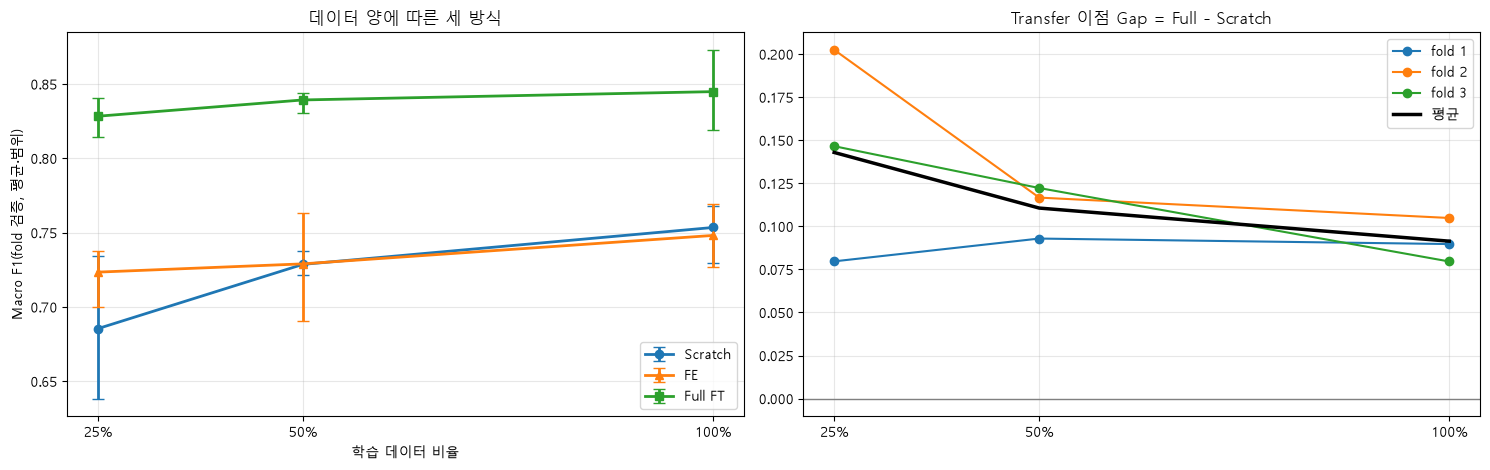

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for s, mk in zip(STRATS, "o^s"):
    g = ds[ds["전략"] == s].groupby("비율")["Macro F1"]
    axes[0].errorbar(PCTS, g.mean(), yerr=[g.mean() - g.min(), g.max() - g.mean()], marker=mk, capsize=4, lw=2, label=LABEL[s])
axes[0].set_xticks(PCTS); axes[0].set_xticklabels([f"{p}%" for p in PCTS]); axes[0].set_xlabel("학습 데이터 비율")
axes[0].set_ylabel("Macro F1(fold 검증, 평균·범위)"); axes[0].legend(); axes[0].grid(alpha=.3); axes[0].set_title("데이터 양에 따른 세 방식")
for f in FOLDS:
    axes[1].plot(PCTS, gap.loc[f"fold {f}", list(PCTS)], marker="o", label=f"fold {f}")
axes[1].plot(PCTS, gap.loc["평균", list(PCTS)], color="k", lw=2.5, label="평균")
axes[1].set_xticks(PCTS); axes[1].set_xticklabels([f"{p}%" for p in PCTS]); axes[1].axhline(0, color="gray", lw=1)
axes[1].set_title("Transfer 이점 Gap = Full - Scratch"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIGURES / "ds_data_size.png", dpi=110); plt.show()

## 2. Q2·Q3: 전략별 데이터 민감도, 25%에서 FE vs Scratch

In [4]:
drop = pd.DataFrame({LABEL[s]: [F[s, 100, f] - F[s, 25, f] for f in FOLDS] for s in STRATS}, index=[f"fold {f}" for f in FOLDS])
drop["가장 덜 떨어진 전략"] = drop.idxmin(axis=1)
drop.loc["평균"] = drop[[LABEL[s] for s in STRATS]].mean()
fe_s = pd.DataFrame({f"{p}%": [F["fe", p, f] - F["scratch", p, f] for f in FOLDS] for p in PCTS}, index=[f"fold {f}" for f in FOLDS])
fe_s.loc["FE > Scratch fold 수"] = (fe_s > 0).sum()
display(drop.round(4)); display(fe_s.round(4))

,Scratch,FE,Full FT,가장 덜 떨어진 전략
fold 1,-0.0049,0.0267,0.0052,Scratch
fold 2,0.1298,0.0318,0.0322,FE
fold 3,0.0792,0.0155,0.0123,Full FT
평균,0.0681,0.0247,0.0165,NaN


,25%,50%,100%
fold 1,-0.0345,-0.0470,-0.0029
fold 2,0.0992,0.0364,0.0012
fold 3,0.0494,0.0117,-0.0144
FE > Scratch fold 수,2.0000,2.0000,1.0000


## 3. 클래스별 Recall과 학습 경과

In [5]:
order = [c for g in GROUPS.values() for c in g]
tab = {}
for s in STRATS:
    for p in PCTS:
        g = ds[(ds["전략"] == s) & (ds["비율"] == p)]
        tab[f"{LABEL[s]} {p}%"] = [g[f"R:{NAMES[c]}"].mean() for c in order]
rt = pd.DataFrame(tab, index=[f"{c} {NAMES[c]}" for c in order]).round(2)
coll = ds.assign(붕괴=ds["최저 Recall"] < 0.20).pivot_table(index="전략", columns="비율", values="붕괴", aggfunc="sum").reindex(STRATS)
display(rt); print("Recall < 0.20 클래스가 있는 fold 수:"); display(coll)

,Scratch 25%,Scratch 50%,Scratch 100%,FE 25%,FE 50%,FE 100%,Full FT 25%,Full FT 50%,Full FT 100%
0 Y - Exercise,0.75,0.71,0.81,0.85,0.89,0.80,0.94,0.96,0.95
1 니푸쉬업,0.99,0.97,1.00,0.97,0.96,0.97,1.00,1.00,1.00
4 라잉 레그 레이즈,0.78,0.79,0.72,0.72,0.71,0.76,0.86,0.89,0.83
10 바이시클 크런치,0.53,0.66,0.69,0.51,0.53,0.61,0.71,0.78,0.84
2 덤벨 벤트오버 로우,0.47,0.50,0.50,0.35,0.50,0.47,0.57,0.58,0.70
7 바벨 데드리프트,0.36,0.53,0.58,0.69,0.56,0.66,0.72,0.75,0.64
8 바벨 런지,0.73,0.84,0.76,0.83,0.89,0.88,0.96,0.97,0.98
9 바벨 로우,0.12,0.05,0.24,0.07,0.03,0.04,0.24,0.21,0.31
3 딥스,0.96,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
5 랫풀 다운,0.84,0.86,0.95,0.93,0.93,0.96,0.98,0.98,0.99


Recall < 0.20 클래스가 있는 fold 수:


비율,25,50,100
전략,,,
scratch,2,3,1
fe,3,3,3
full,2,1,0


In [6]:
ds.groupby(["전략", "비율"]).agg(학습_장수=("학습 장수", "mean"), best_멈춤=("best/멈춤", lambda v: ", ".join(v)),
                               Best_Last_평균=("Best−Last", "mean"), epoch당_초=("epoch당(초)", "mean"), 전체_분=("전체(분)", "mean")
                               ).reindex(STRATS, level=0).round(3)

학습_장수              best_멈춤  Best_Last_평균  epoch당_초   전체_분
전략      비율                                                               
scratch 25   1597.333  22/27, 12/17, 23/28         0.025     2.517  3.080
        50   3194.667   9/14, 20/25, 14/19         0.027     4.394  3.040
        100  6389.333   7/12, 19/24, 24/29         0.021     7.759  4.574
fe      25   1597.333  17/22, 15/20, 21/26         0.014     1.826  2.675
        50   3194.667   5/10, 25/30, 17/22         0.013     3.160  2.784
        100  6389.333   10/15, 13/18, 9/14         0.023     5.406  2.739
full    25   1597.333  14/19, 11/16, 13/18         0.030     2.717  2.312
        50   3194.667  13/18, 18/23, 16/21         0.006     4.311  3.253
        100  6389.333    7/12, 5/10, 13/18         0.006     8.611  3.120

## 4. 해석

### 판정(실행 전 기준 그대로)

- **Q1 "데이터가 적을수록 Transfer 이점이 커진다": 구분 불가.**
  - Gap(25) − Gap(100)은 fold 2에서 +0.098, fold 3에서 +0.067로 컸습니다. fold 1은 −0.010으로 방향이 반대였습니다.
  - 평균 차이는 +0.052로 기준 +0.020의 2배를 넘습니다. 그래도 "세 fold 모두"라는 조건을 못 채워 지지가 아닙니다. "반대"(2개 fold 이상)도 아닙니다.
  - 평균 Gap은 25% 0.143 → 50% 0.111 → 100% 0.091로 줄어드는 모양입니다. 예상과 같은 방향이지만, 한 fold가 따르지 않아 기준상 결론을 내리지 않습니다.
- **fold 1이 따르지 않은 이유**: Full이 아니라 Scratch 쪽에 있습니다. fold 1의 Scratch는 25% 0.734, 50% 0.738, 100% 0.730으로 데이터 양과 거의 상관이 없었습니다. fold 2·3의 Scratch는 25%에서 0.638·0.684로 크게 떨어졌습니다. CV에서 Scratch의 seed 흔들림은 재지 않았습니다(seed sd 0.008~0.011은 Full FT 값). 그래서 fold 1이 "그 사람들에게는 데이터 양이 덜 중요했다"인지 "seed 1개의 운"인지는 이 실험으로 가를 수 없습니다.

### 기술 결과(판정 없음)

- **Q2 데이터 민감도**(100% → 25%로 줄었을 때 잃은 F1, fold 평균): Scratch 0.068, FE 0.025, Full FT 0.017.
  - 사전학습을 쓴 두 방식은 데이터를 1/4로 줄여도 0.02 안팎만 잃었습니다. Scratch는 fold 2에서 0.130을 잃었습니다.
  - fold 1만 예외로, Scratch가 오히려 0.005 올랐습니다(위 설명).
- **Full FT 25%가 Scratch 100%보다 높았습니다.** 세 fold 모두입니다(0.814 vs 0.730, 0.841 vs 0.768, 0.830 vs 0.763). 학습 사진 약 1,600장으로 미세조정한 모델이 약 6,400장으로 처음부터 배운 모델을 이겼습니다. 이 실험에서 가장 분명한 결과입니다.
- **Q3 FE vs Scratch**: 25%에서는 FE가 2/3 fold에서 높았고, 100%에서는 1/3 fold였습니다. 공식 Val에서 "FE < Scratch"(E02 < E01)였던 것은 데이터가 충분할 때의 이야기이고, 데이터가 적으면 순서가 뒤집히는 경향이 보입니다. fold 1은 모든 비율에서 FE가 낮아 한결같지는 않습니다.
- **Full FT 50%와 100%의 차이는 0.006**에 그쳤습니다. fold 1은 50%가 100%보다 높았습니다(0.831 vs 0.819). 이 과제에서 Full FT는 학습 사진을 절반으로 줄여도 거의 잃지 않습니다.

### 클래스별로 보면

- **기구·맨몸 운동**(딥스, 로잉머신, 니푸쉬업, 랫풀 다운, 케이블 크런치)은 25%에서도 세 방식 모두 0.83 이상입니다. 기구 모양이 분명해서 적은 사진으로도 배웁니다.
- **데이터를 줄이면 무너지는 곳은 바벨·덤벨 묶음**입니다. Scratch의 바벨 데드리프트는 0.58 → 0.36, 바이시클 크런치는 0.69 → 0.53이 됐습니다. 이 운동들은 같은 바벨을 들고 상체 각도·무릎 각도처럼 자세의 미세한 차이로 구분됩니다. 그런 특징은 사진이 적을수록 배우기 어렵습니다.
- **바벨 로우는 어떤 조건에서도 풀리지 않았습니다**(Recall 0.03~0.31). 붕괴(Recall < 0.20)가 있는 fold 수는 FE가 모든 비율에서 3/3이었고, Full FT는 25%에서 2, 50%에서 1, 100%에서 0이었습니다. 데이터가 많을수록 바벨 로우가 조금씩 살아나는 것은 Full FT뿐입니다. 진단 분석(15번)에서 본 것처럼 바벨 로우는 데드리프트의 중간 자세와 겹치므로, 사진 수보다 "구분되는 순간이 담긴 사진"이 문제일 가능성이 있습니다(가설).

### 학습 경과

- epoch당 시간은 학습 장수에 비례해 줄었습니다(Full FT 8.6초 → 2.7초). 그 대신 적은 데이터에서는 더 오래 돌아(Scratch 25%는 17~28 epoch), 전체 시간은 2.3~4.6분으로 비율 사이 차이가 작았습니다.
- 계획에 적은 대로, patience를 epoch로 정했기 때문에 25%에서는 epoch당 학습 단계가 1/4입니다. 결과는 "같은 멈춤 규칙을 적용했을 때"로 읽습니다.

### 한계

- seed 1개, fold 3개(학습 데이터가 겹쳐 독립 표본이 아님). 유의성은 주장하지 않습니다.
- fold 점수는 Early Stopping과 같은 데이터에서 나와 낙관적입니다. 방식·비율 사이 비교용입니다.
- 결과로 최종 모델(E08)을 바꾸지 않았습니다. 2단계(seed 추가)는 미리 두지 않았습니다.

### 배운 점

- **사전학습의 가치는 "데이터를 아끼는 능력"으로 가장 분명히 드러났습니다.** 평균 이점이 데이터가 적을수록 커지는 모양은 보였지만 fold 하나가 따르지 않았습니다. 반면 "Full FT 25% > Scratch 100%"는 세 fold 모두에서 나왔습니다.
- **평균만 봤다면 "지지"라고 썼을 것입니다**(평균 차이 +0.052). fold별 방향을 함께 보는 기준을 미리 정해 두었기 때문에, 한 fold의 반대 결과를 숨기지 않고 "구분 불가"로 적을 수 있었습니다.
- Scratch의 결과는 Transfer보다 흔들림이 클 수 있습니다. 처음부터 배우는 모델은 초기값과 데이터 순서에 더 민감합니다. Scratch를 기준선으로 쓰는 비교에서는 Scratch의 seed 흔들림도 재야 해석이 단단해집니다.